# Clean SAXS calculation with Mark1300 extraction

This notebook runs four beam configurations through the same `PCI.py` wire and SAXS detector model: Mark1300-compatible divergent beams with 6 µm and 7.5 µm target-plane intensity FWHM, plus weakly divergent, large-root Gaussian beams with the same target-plane FWHMs. Every configuration saves float32 detector TIFFs, reopens those TIFFs, averages exactly the two central rows, excludes the central $|q_x| < 0.10$ nm$^{-1}$ band, and writes raw left/right signals in the legacy three-column format (offset nm, left, right).

Here *collimated* denotes the larger Gaussian source-waist root at the same 0.25 m source-to-target distance. This branch has lower divergence and weaker target-plane curvature than the smaller-root branch, while reproducing the requested target-plane FWHM; it is quasi-collimated rather than exactly planar.

In [1]:
from pathlib import Path
import pickle
import sys

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np
from PIL import Image
from scipy import interpolate
from scipy.ndimage import shift as nd_shift

ROOT = Path.cwd()
SAXS_DIR = ROOT / "SAXS_asymmetry" if (ROOT / "SAXS_asymmetry" / "PCI.py").exists() else ROOT
INPUT_DIR = SAXS_DIR / "inputs"
OUTPUT_DIR = SAXS_DIR / "outputs"
if str(SAXS_DIR) not in sys.path:
    sys.path.insert(0, str(SAXS_DIR))
import PCI

N_GRID = 4096
PIXEL_SIZE = 8 * PCI.nm
PHOTON_ENERGY = 8.2 * PCI.keV
LAMBDA_NM = PCI.HC_KEV_NM / PHOTON_ENERGY
SOURCE_TO_TARGET = 0.25 * PCI.m
TARGET_TO_DETECTOR = 1.31 * PCI.m
WIRE_RADIUS = 5 * PCI.um
VOXEL_SIZE = 20 * PCI.nm
VOXEL_NUMBER = 2000
OFFSET_STEP = 2.5
OFFSETS = np.arange(-10, 10 + OFFSET_STEP / 2, OFFSET_STEP) * PCI.um

def fwhm_tag(fwhm_nm):
    return f"{fwhm_nm / PCI.um:g}".replace(".", "p")

def target_radius_from_fwhm(fwhm_nm):
    """Convert intensity FWHM to PCI.py's 1/e² intensity radius."""
    return fwhm_nm / np.sqrt(2 * np.log(2))

def divergent_source_waist(fwhm_nm):
    """Smaller Gaussian-waist root giving `fwhm_nm` at the target."""
    target_radius = target_radius_from_fwhm(fwhm_nm)
    diffraction_term = LAMBDA_NM * SOURCE_TO_TARGET / np.pi
    discriminant = target_radius**4 - 4 * diffraction_term**2
    if discriminant < 0:
        raise ValueError("requested target FWHM is below the diffraction limit")
    return np.sqrt((target_radius**2 - np.sqrt(discriminant)) / 2)

def collimated_source_waist(fwhm_nm):
    """Large Gaussian-waist root giving `fwhm_nm` at the target."""
    target_radius = target_radius_from_fwhm(fwhm_nm)
    diffraction_term = LAMBDA_NM * SOURCE_TO_TARGET / np.pi
    discriminant = target_radius**4 - 4 * diffraction_term**2
    if discriminant < 0:
        raise ValueError("requested target FWHM is below the diffraction limit")
    return np.sqrt((target_radius**2 + np.sqrt(discriminant)) / 2)

def make_case(*, fwhm_um, collimated):
    fwhm_nm = fwhm_um * PCI.um
    tag = fwhm_tag(fwhm_nm)
    if collimated:
        # Use the broad-waist, weakly divergent root while retaining the
        # same source-to-target geometry and requested target-plane FWHM.
        source_waist = collimated_source_waist(fwhm_nm)
        target_position = SOURCE_TO_TARGET
        name = f"collimated_{tag}um"
        label = f"Collimated (large-root), {fwhm_um:g} µm FWHM at target"
        table_name = f"CollimatedSAXS_asymmetry_Mark1300_{tag}um.dat"
    else:
        source_waist = divergent_source_waist(fwhm_nm)
        target_position = SOURCE_TO_TARGET
        name = f"mark1300_{tag}um"
        label = f"Mark1300 divergent, {fwhm_um:g} µm FWHM at target"
        table_name = f"DivSAXS_asymmetry_Mark1300_{tag}um.dat"
    case_output_dir = OUTPUT_DIR / "saxs"
    return {
        "name": name, "label": label, "fwhm_nm": fwhm_nm,
        "source_waist": source_waist, "target_position": target_position,
        "detector_position": target_position + TARGET_TO_DETECTOR,
        "results_dir": case_output_dir / "figures" / f"Results_{PIXEL_SIZE:g}nm" / name,
        "data_dir": case_output_dir / "detector_tiffs" / f"Data_{PIXEL_SIZE:g}nm" / name,
        "table_path": case_output_dir / "tables" / table_name,
    }

BEAM_CASES = {
    case["name"]: case
    for case in (
        make_case(fwhm_um=6.0, collimated=False),
        make_case(fwhm_um=7.5, collimated=False),
        make_case(fwhm_um=6.0, collimated=True),
        make_case(fwhm_um=7.5, collimated=True),
    )
}
# Run sequentially: every 4096² propagation is memory-intensive.
RUN_CASES = tuple(BEAM_CASES)
for case in BEAM_CASES.values():
    case["results_dir"].mkdir(parents=True, exist_ok=True)
    case["data_dir"].mkdir(parents=True, exist_ok=True)
    case["table_path"].parent.mkdir(parents=True, exist_ok=True)

class projected_wire(PCI.wire):
    """Memory-efficient 2-D equivalent of PCI.wire's voxel projection."""
    def _get_projection(self, volume=None):
        transverse_px = np.arange(self.voxel_number) - self.voxel_number // 2
        radius_px = self.radius1_nm / self.voxel_size
        inside = np.clip(radius_px**2 - transverse_px**2, 0, None)
        profile = np.where(
            np.abs(transverse_px) <= radius_px,
            (2 * np.floor(np.sqrt(inside)) + 1) * self.voxel_size,
            0.0,
        )[None, :]
        projection = np.broadcast_to(
            profile, (self.voxel_number, self.voxel_number)
        ).copy()
        self._density1 = nd_shift(
            projection, np.asarray(self.position_xy) / self.voxel_size,
            order=1, mode="constant", cval=0, prefilter=False,
        )
        return self._density1


PCI successfully compiled. You can get more help by typing 'PCI.help()'


  This program comes with ABSOLUTELY NO WARRANTY; for details type `show w'.
  This is free software, and you are welcome to redistribute it
  under certain conditions; type `show c' for details.


In [2]:
q_max = np.pi / PIXEL_SIZE
q_axis = np.linspace(-q_max, q_max, N_GRID)
q_step = 2 * np.pi / (N_GRID * PIXEL_SIZE)
q_extent = [-q_step * N_GRID / 2, q_step * N_GRID / 2] * 2
MARK1300_Q_MIN = 0.10
MARK1300_CENTER_HALF_WIDTH_PIXELS = int(np.round(MARK1300_Q_MIN / q_step))

experimental_profiles = {}
run_scales = {528: 50e3, 534: 80e3, 546: 80e3}
for run, scale in run_scales.items():
    path = INPUT_DIR / "experimental" / "SAXSData" / f"profiles_cleaned_p3129_r{run:04d}.pickle"
    with path.open("rb") as stream:
        experimental = pickle.load(stream)
    experimental = [np.nan_to_num(values, nan=0.0) for values in experimental]
    q_values = np.concatenate((np.flip(-experimental[0])[:-1], experimental[0]))
    lineout = np.concatenate((np.flip(experimental[1])[:-1], experimental[2]))
    experimental_profiles[run] = (q_values, lineout / lineout.max() / scale)
q_run528 = experimental_profiles[528][0]

def simulate_offset(case, offset):
    target = projected_wire(
        "wire", photon_Energy=PHOTON_ENERGY, radius=WIRE_RADIUS, material=PCI.Cu,
        position=[0, offset, case["target_position"]],
        voxel_size=VOXEL_SIZE, voxel_number=VOXEL_NUMBER,
    )
    xfel = PCI.gaussian_XFEL(
        waist=case["source_waist"], pixel_number=N_GRID, pixel_size=PIXEL_SIZE,
        photon_energy=PHOTON_ENERGY, photon_energy_bandwidth=0 * PCI.eV,
        photon_energy_bandwidth_sample_width=0 * PCI.eV,
    )
    detector = PCI.jungfrau(
        "SAXS", category="SAXS", XFEL=xfel,
        position=[0, 0, case["detector_position"]],
    )
    PCI.Beamline(target=target, XFEL=xfel, detector=detector).propagate_XFEL_to(
        detector=detector
    )
    offset_um = float(offset / PCI.um)
    detector_tif_path = case["data_dir"] / f"SAXS_Offset{offset_um:.2f}um.tif"
    Image.fromarray(np.asarray(xfel.intensity_detector, dtype=np.float32)).save(
        detector_tif_path, format="TIFF", compression="tiff_deflate",
    )
    # Mark1300-compatible extraction always uses the reopened TIFF.
    with Image.open(detector_tif_path) as detector_image:
        saxs_intensity = np.asarray(detector_image, dtype=np.float32).copy()
    center = N_GRID // 2
    mark_lineout = saxs_intensity[center - 1:center + 1, :].mean(axis=0)
    mark_left = float(mark_lineout[:center - MARK1300_CENTER_HALF_WIDTH_PIXELS].sum())
    mark_right = float(mark_lineout[center + MARK1300_CENTER_HALF_WIDTH_PIXELS:].sum())
    mark_left_fraction = mark_left / (mark_left + mark_right)
    lineout = interpolate.interp1d(
        q_axis, mark_lineout, fill_value="extrapolate"
    )(q_run528)
    lineout = lineout / lineout.max() * 2
    output_path = case["results_dir"] / (
        f"SAXS_offset{offset_um:.1f}um_{case['name']}_"
        f"Pix{PIXEL_SIZE:g}nm_D{TARGET_TO_DETECTOR / PCI.m:.2f}m.png"
    )
    fig, axes = plt.subplots(2, 1, figsize=(10, 8))
    image = axes[0].imshow(
        saxs_intensity, origin="lower", extent=q_extent, aspect="auto",
        cmap="inferno", norm=LogNorm(vmin=1e-11, vmax=5e-8),
    )
    axes[0].set(
        xlabel=r"$Q_x$ [nm$^{-1}$]", ylabel=r"$Q_y$ [nm$^{-1}$]",
        title=f"{case['label']}, offset {offset_um:.1f} µm, L/(L+R)={mark_left_fraction:.4f}",
        xlim=(-0.4, 0.4), ylim=(-0.005, 0.005),
    )
    fig.colorbar(image, ax=axes[0], label="Intensity")
    axes[1].semilogy(q_run528, lineout, "--", label=f"Simulated {offset_um:.1f} µm")
    for run, (q_values, experimental_lineout) in experimental_profiles.items():
        axes[1].semilogy(
            q_values, experimental_lineout, "o-", markersize=3, label=f"Exp. Run {run}"
        )
    axes[1].set(
        xlabel=r"$Q_x$ [nm$^{-1}$]", ylabel="Normalized intensity",
        xlim=(-0.4, 0.4), ylim=(1e-8, 5e-4),
    )
    axes[1].grid(alpha=0.25)
    axes[1].legend()
    fig.tight_layout()
    fig.savefig(output_path, dpi=200, bbox_inches="tight")
    plt.close(fig)
    return {
        "offset_um": offset_um, "left": mark_left, "right": mark_right,
        "left_fraction": mark_left_fraction, "tif_path": detector_tif_path,
    }

simulated_asymmetry = {}
for case_name in RUN_CASES:
    case = BEAM_CASES[case_name]
    print(f"Running {case['label']}", flush=True)
    simulated_asymmetry[case_name] = [
        simulate_offset(case, offset) for offset in OFFSETS
    ]


Running Mark1300 divergent, 6 µm FWHM at target
Rayleigh [m]:  0.16837868596938366
Radius [um]:  363405.5275551053 0.15120024068359483
the beam waist on the target plane is  5.096 um
the FWHM beam waist on the target plane is  6.000 um
the target postion is 0.250 m
complex q parameter is (249999999.99999997+168378685.96938363j)
mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000


"Sorry, due to the detector type 'SAXS', bandwidth not taken into account in propagation from last target to detector!"


Rayleigh [m]:  0.16837868596938366
Radius [um]:  363405.5275551053 0.15120024068359483
the beam waist on the target plane is  5.096 um
the FWHM beam waist on the target plane is  6.000 um
the target postion is 0.250 m
complex q parameter is (249999999.99999997+168378685.96938363j)
mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000


"Sorry, due to the detector type 'SAXS', bandwidth not taken into account in propagation from last target to detector!"


Rayleigh [m]:  0.16837868596938366
Radius [um]:  363405.5275551053 0.15120024068359483
the beam waist on the target plane is  5.096 um
the FWHM beam waist on the target plane is  6.000 um
the target postion is 0.250 m
complex q parameter is (249999999.99999997+168378685.96938363j)
mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000


"Sorry, due to the detector type 'SAXS', bandwidth not taken into account in propagation from last target to detector!"


... (62 outputs left out)

Rayleigh [m]:  0.7609359013590985
Radius [um]:  2566093.7839087346 0.15120024068359483
the beam waist on the target plane is  6.370 um
the FWHM beam waist on the target plane is  7.500 um
the target postion is 0.250 m
complex q parameter is (249999999.99999997+760935901.3590983j)
mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000


"Sorry, due to the detector type 'SAXS', bandwidth not taken into account in propagation from last target to detector!"


Rayleigh [m]:  0.7609359013590985
Radius [um]:  2566093.7839087346 0.15120024068359483
the beam waist on the target plane is  6.370 um
the FWHM beam waist on the target plane is  7.500 um
the target postion is 0.250 m
complex q parameter is (249999999.99999997+760935901.3590983j)
mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000


"Sorry, due to the detector type 'SAXS', bandwidth not taken into account in propagation from last target to detector!"


In [3]:
print(f"Mark1300 extraction: two center rows, ±{MARK1300_CENTER_HALF_WIDTH_PIXELS} pixels excluded")
print(f"Effective q cutoff: {MARK1300_CENTER_HALF_WIDTH_PIXELS * q_step:.6f} nm⁻¹")
for case_name in RUN_CASES:
    case = BEAM_CASES[case_name]
    records = simulated_asymmetry[case_name]
    table = np.array([
        [record["offset_um"] * 1e3, record["left"], record["right"]]
        for record in records
    ])
    np.savetxt(
        case["table_path"], table,
        header=("offset_nm left_raw right_raw; Mark1300 two-row extraction; "
                f"{case['label']}"),
    )
    print(
        f"{case['label']}: source radius={case['source_waist'] / PCI.um:.6f} µm, "
        f"target z={case['target_position'] / PCI.m:g} m, {len(records)} offsets"
    )
    print(f"  table: {case['table_path']}")
    print(f"  TIFFs: {case['data_dir']}")


Mark1300 extraction: two center rows, ±522 pixels excluded
Effective q cutoff: 0.100092 nm⁻¹
Mark1300 divergent, 6 µm FWHM at target: source radius=2.846721 µm, target z=0.25 m, 9 offsets
  table: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\saxs\tables\DivSAXS_asymmetry_Mark1300_6um.dat
  TIFFs: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\saxs\detector_tiffs\Data_8nm\mark1300_6um
Mark1300 divergent, 7.5 µm FWHM at target: source radius=1.988233 µm, target z=0.25 m, 9 offsets
  table: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\saxs\tables\DivSAXS_asymmetry_Mark1300_7p5um.dat
  TIFFs: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\saxs\detector_tiffs\Data_8nm\mark1300_7p5um
Collimated (large-root), 6 µm FWHM at target: source radius=4.226664 µm, target z=0.25 m, 9 offsets
  table: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\saxs\tables\C

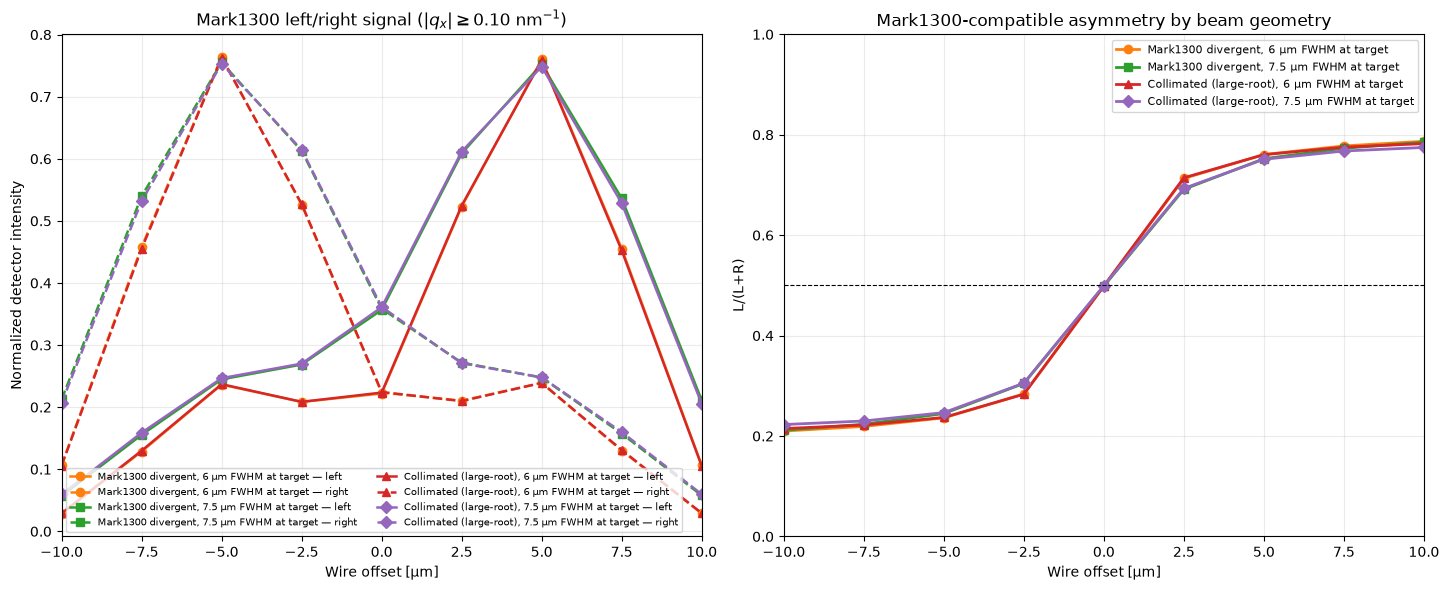

Saved comparison: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\saxs\figures\SAXS_Mark1300_collimated_6um_7p5um.png


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
styles = {
    "mark1300_6um": dict(color="tab:orange", marker="o"),
    "mark1300_7p5um": dict(color="tab:green", marker="s"),
    "collimated_6um": dict(color="tab:red", marker="^"),
    "collimated_7p5um": dict(color="tab:purple", marker="D"),
}
for case_name in RUN_CASES:
    case = BEAM_CASES[case_name]
    records = simulated_asymmetry[case_name]
    offsets_um = np.array([record["offset_um"] for record in records])
    left = np.array([record["left"] for record in records])
    right = np.array([record["right"] for record in records])
    total_scale = np.nanmax(left + right)
    style = styles[case_name]
    axes[0].plot(
        offsets_um, left / total_scale, linestyle="-", linewidth=1.8,
        label=f"{case['label']} — left", **style,
    )
    axes[0].plot(
        offsets_um, right / total_scale, linestyle="--", linewidth=1.8,
        label=f"{case['label']} — right", **style,
    )
    axes[1].plot(
        offsets_um, left / (left + right), linestyle="-", linewidth=2,
        label=case["label"], **style,
    )
axes[0].set(
    xlabel="Wire offset [µm]", ylabel="Normalized detector intensity",
    title=r"Mark1300 left/right signal ($|q_x| \geq 0.10$ nm$^{-1}$)",
    xlim=(-10, 10),
)
axes[0].grid(alpha=0.25)
axes[0].legend(fontsize=7, ncol=2)
axes[1].axhline(0.5, color="k", linewidth=0.8, linestyle="--")
axes[1].set(
    xlabel="Wire offset [µm]", ylabel="L/(L+R)",
    title="Mark1300-compatible asymmetry by beam geometry",
    xlim=(-10, 10), ylim=(0, 1),
)
axes[1].grid(alpha=0.25)
axes[1].legend(fontsize=8)
fig.tight_layout()
comparison_path = OUTPUT_DIR / "saxs" / "figures" / "SAXS_Mark1300_collimated_6um_7p5um.png"
fig.savefig(comparison_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved comparison: {comparison_path}")
